In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Đọc dữ liệu đã làm sạch (1.210 nhà hàng Hà Nội)
df = pd.read_csv('hanoi_restaurants_cleaned.csv')

# 2. Tạo các cột đặc trưng phục vụ trực quan hóa
hoalac_areas = ['Hòa Lạc', 'Thạch Hòa', 'Tân Xã', 'Bắc Phú Cát', 'Thạch Thất',
                'Liên Quan', 'Tây Phương', 'Yên Bình', 'Bình Yên', 'Phú Cát']

df['Region'] = np.where(df['Locality'].isin(hoalac_areas), 'Hoa Lac Area (210)', 'Inner Hanoi (1000)')
df['Is_HoaLac'] = df['Locality'].isin(hoalac_areas).astype(int)
df['Has_Online_Delivery_Num'] = (df['Has Online delivery'] == 'Yes').astype(int)
df['Has_Table_Booking_Num'] = (df['Has Table booking'] == 'Yes').astype(int)
df['Cuisine_Count'] = df['Cuisines'].apply(lambda x: len(str(x).split(',')))

# Thiết lập giao diện chung
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

**Phân phối Điểm đánh giá và Chi phí tại Hà Nội**

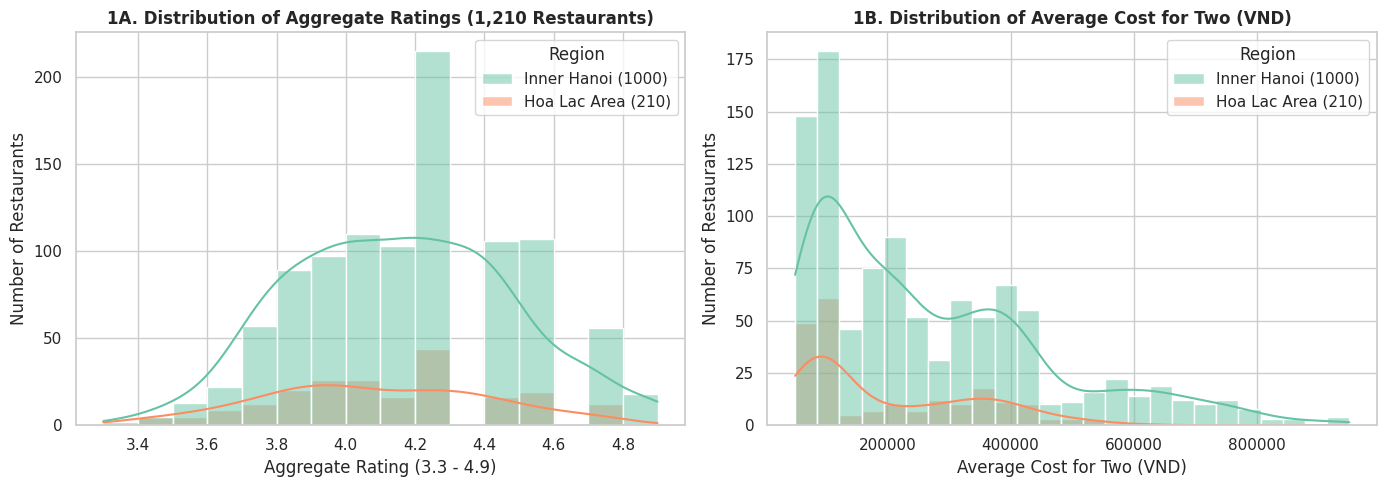

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1A: Phân phối điểm đánh giá (Aggregate rating)
sns.histplot(data=df, x='Aggregate rating', hue='Region', bins=16, kde=True, palette='Set2', ax=axes[0])
axes[0].set_title("1A. Distribution of Aggregate Ratings (1,210 Restaurants)", fontweight='bold')
axes[0].set_xlabel("Aggregate Rating (3.3 - 4.9)")
axes[0].set_ylabel("Number of Restaurants")

# 1B: Phân phối chi phí cho 2 người (Average Cost for two)
sns.histplot(data=df, x='Average Cost for two', hue='Region', bins=25, kde=True, palette='Set2', ax=axes[1])
axes[1].set_title("1B. Distribution of Average Cost for Two (VND)", fontweight='bold')
axes[1].set_xlabel("Average Cost for Two (VND)")
axes[1].set_ylabel("Number of Restaurants")

plt.tight_layout()
plt.show()

/tmp/ipykernel_1304/987699043.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=top_cuisines.values, y=top_cuisines.index, palette='Blues_r')


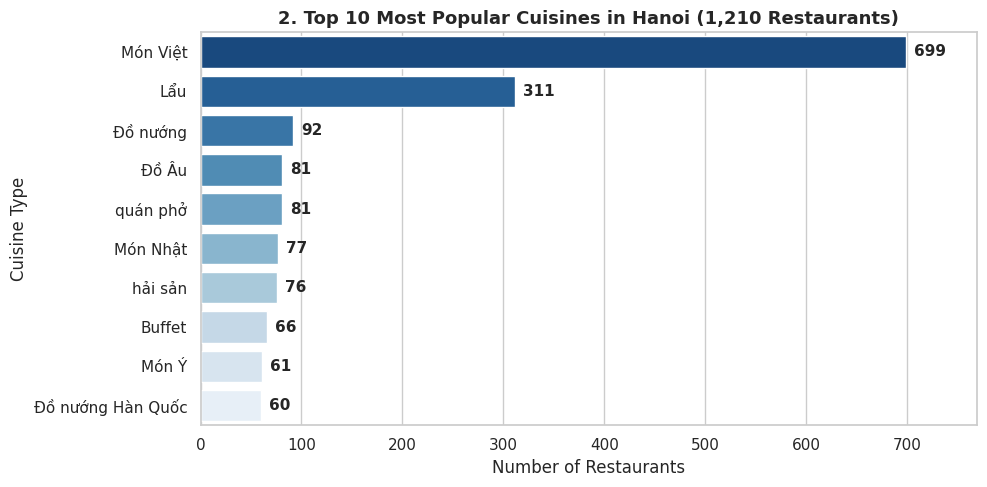

In [ ]:
# Tách chuỗi Cuisines và đếm tần suất Top 10
cuisine_series = df['Cuisines'].dropna().str.split(',').explode().str.strip()
top_cuisines = cuisine_series.value_counts().head(10)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=top_cuisines.values, y=top_cuisines.index, palette='Blues_r')

# Hiển thị số lượng cụ thể trên từng thanh
for i, v in enumerate(top_cuisines.values):
    ax.text(v + 8, i, str(v), va='center', fontweight='bold')

plt.title("2. Top 10 Most Popular Cuisines in Hanoi (1,210 Restaurants)", fontsize=13, fontweight='bold')
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine Type")
plt.xlim(0, max(top_cuisines.values) * 1.1)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1304/2878604833.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Price range', y='Aggregate rating', data=df, palette='Set2', ax=axes[0])
/tmp/ipykernel_1304/2878604833.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Price range', y='Votes', data=df, palette='Set2', errorbar=None, ax=axes[1])


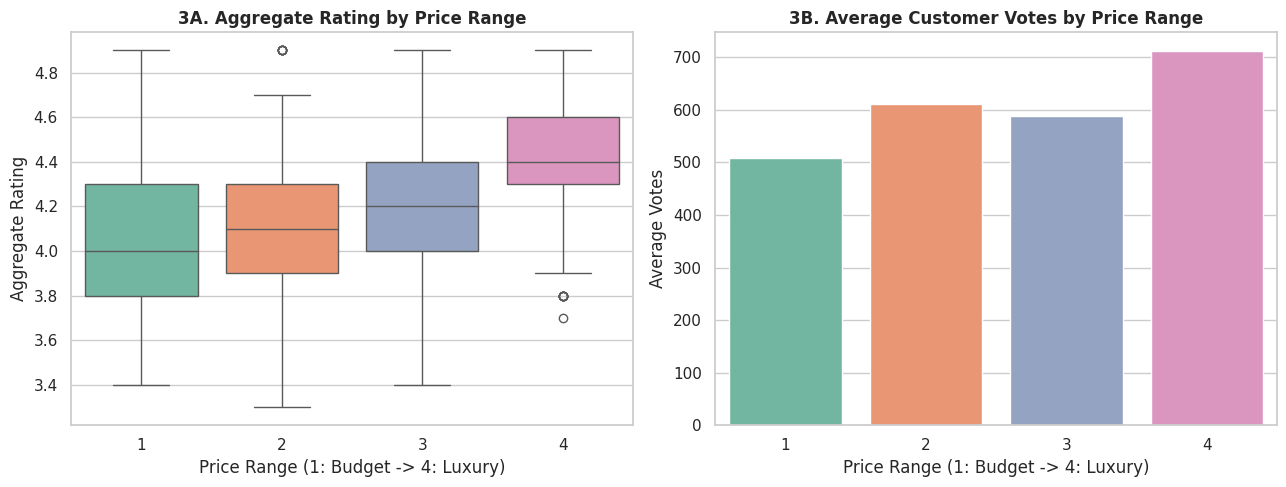

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 3A: Boxplot Điểm đánh giá theo Phân khúc giá
sns.boxplot(x='Price range', y='Aggregate rating', data=df, palette='Set2', ax=axes[0])
axes[0].set_title("3A. Aggregate Rating by Price Range", fontweight='bold')
axes[0].set_xlabel("Price Range (1: Budget -> 4: Luxury)")
axes[0].set_ylabel("Aggregate Rating")

# 3B: Barplot Lượt bình chọn trung bình theo Phân khúc giá
sns.barplot(x='Price range', y='Votes', data=df, palette='Set2', errorbar=None, ax=axes[1])
axes[1].set_title("3B. Average Customer Votes by Price Range", fontweight='bold')
axes[1].set_xlabel("Price Range (1: Budget -> 4: Luxury)")
axes[1].set_ylabel("Average Votes")

plt.tight_layout()
plt.show()

/tmp/ipykernel_1304/606003944.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Has Table booking', y='Aggregate rating', data=df, palette='pastel', ax=axes[0])


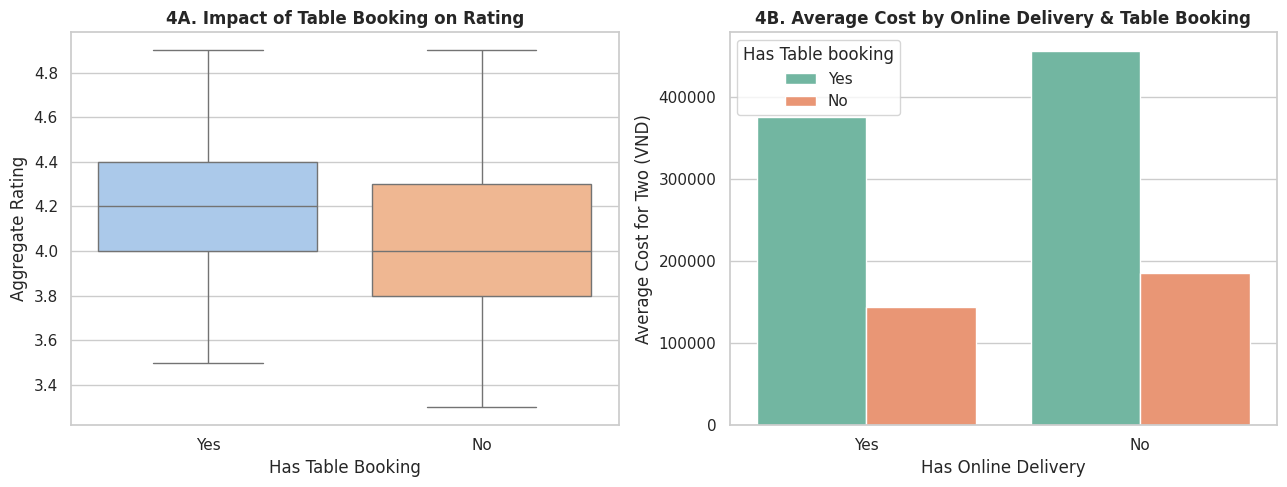

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 4A: So sánh điểm đánh giá theo dịch vụ Đặt bàn trước
sns.boxplot(x='Has Table booking', y='Aggregate rating', data=df, palette='pastel', ax=axes[0])
axes[0].set_title("4A. Impact of Table Booking on Rating", fontweight='bold')
axes[0].set_xlabel("Has Table Booking")
axes[0].set_ylabel("Aggregate Rating")

# 4B: So sánh chi phí trung bình theo Giao hàng và Đặt bàn
sns.barplot(x='Has Online delivery', y='Average Cost for two', hue='Has Table booking',
            data=df, palette='Set2', errorbar=None, ax=axes[1])
axes[1].set_title("4B. Average Cost by Online Delivery & Table Booking", fontweight='bold')
axes[1].set_xlabel("Has Online Delivery")
axes[1].set_ylabel("Average Cost for Two (VND)")

plt.tight_layout()
plt.show()

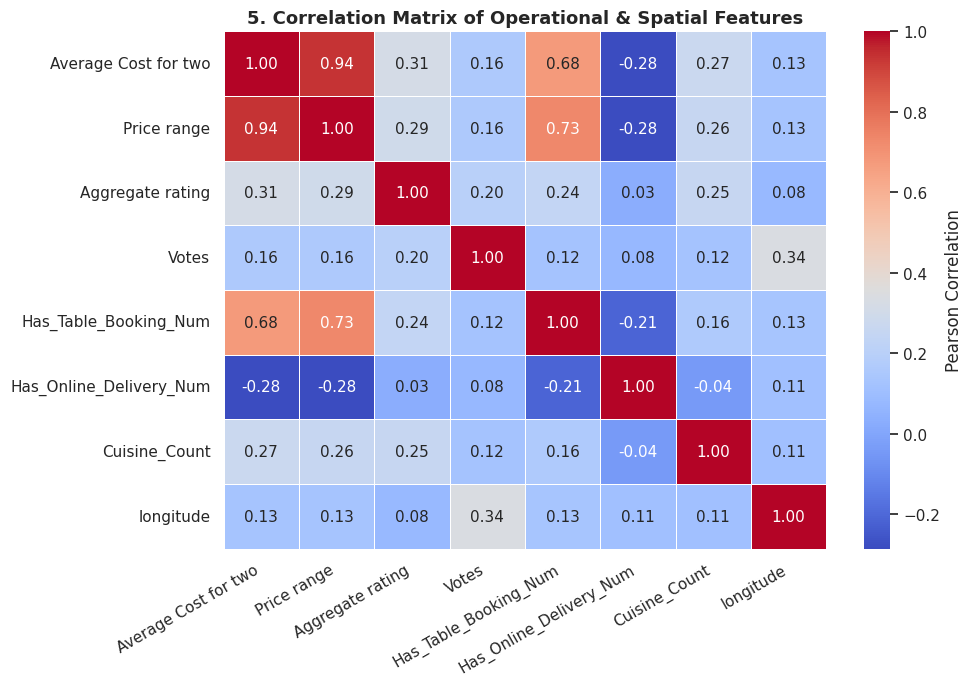

In [ ]:
num_cols = ['Average Cost for two', 'Price range', 'Aggregate rating', 'Votes',
            'Has_Table_Booking_Num', 'Has_Online_Delivery_Num', 'Cuisine_Count', 'longitude']
corr_matrix = df[num_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5,
            cbar_kws={'label': 'Pearson Correlation'})
plt.title("5. Correlation Matrix of Operational & Spatial Features", fontsize=13, fontweight='bold')

# Xoay nhãn trục X nghiêng 30 độ để không bị đè chữ
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1304/2295266764.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=hl_loc.values, y=hl_loc.index, palette='Greens_r', ax=axes[1])


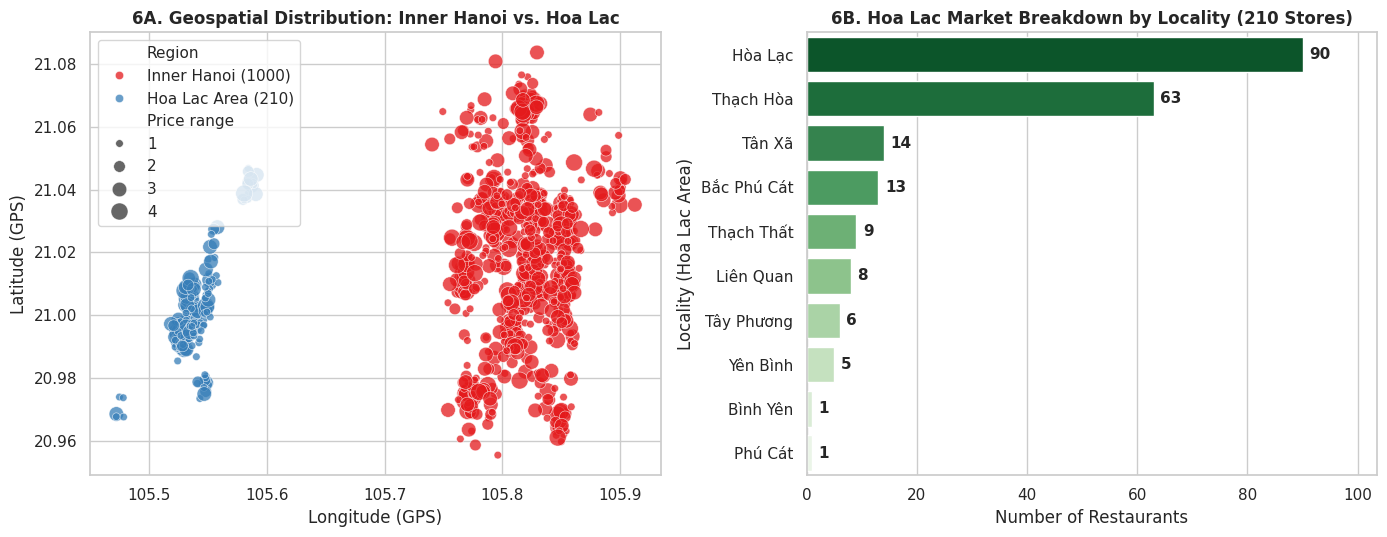

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 6A: Bản đồ phân tán tọa độ GPS (Nội thành Hà Nội vs. Hòa Lạc)
sns.scatterplot(data=df, x='longitude', y='latitude', hue='Region', size='Price range',
                sizes=(30, 150), alpha=0.75, palette='Set1', ax=axes[0])
axes[0].set_title("6A. Geospatial Distribution: Inner Hanoi vs. Hoa Lac", fontweight='bold')
axes[0].set_xlabel("Longitude (GPS)")
axes[0].set_ylabel("Latitude (GPS)")

# 6B: Phân bố số lượng quán ăn tại 10 xã/khu vực thuộc cụm Hòa Lạc (210 quán)
hl_df = df[df['Is_HoaLac'] == 1]
hl_loc = hl_df['Locality'].value_counts()

sns.barplot(x=hl_loc.values, y=hl_loc.index, palette='Greens_r', ax=axes[1])
for i, v in enumerate(hl_loc.values):
    axes[1].text(v + 1.2, i, str(v), va='center', fontweight='bold')

axes[1].set_title("6B. Hoa Lac Market Breakdown by Locality (210 Stores)", fontweight='bold')
axes[1].set_xlabel("Number of Restaurants")
axes[1].set_ylabel("Locality (Hoa Lac Area)")
axes[1].set_xlim(0, max(hl_loc.values) * 1.15)

plt.tight_layout()
plt.show()